# Тестовое задание: Аналитик данных
**Кандидат:** Иван Соловьев  
**Дата:** октябрь 2026  
**Инструменты:** Python (Pandas, Matplotlib), SQL (DuckDB)

## Описание задания
Анализ транзакционных данных интернет-магазина: исследование покупательского поведения, выявление аномалий в данных, построение визуализаций и выполнение аналитических SQL-запросов.

## Структура данных
- **purchases.csv** (6 462 строки) — информация о покупках: источник трафика, ID покупки, сумма, дата и время
- **products.csv** (20 769 строк) — информация о товарах в покупках: ID покупки, ID товара, цена

## Ключевые находки
- Обнаружены товары с нулевой ценой (вероятно, технические/бонусные позиции)
- Выявлен артефакт неполной выгрузки данных за 1 июня 2025 г.
- Источник `organic` показывает наибольшую долю уникальных товаров

# Часть 1. Анализ данных с использованием Python (Pandas)

### Подготовка данных
Для начала данные были загружены, очищены от дубликатов (их не обнаружено) и объединены по ключу `purchase_id` для получения единого датафрейма `df`, содержащего информацию как о покупках, так и о товарах.

In [69]:
import pandas as pd


In [70]:
# Загрузка данных
products = pd.read_csv('products.csv')
purchases = pd.read_csv('purchases.csv')

In [71]:
products.head()

,productsPurchaseID,productsID,productsPrice
0,60323068,58627,4590.0
1,60323068,137958,0.0
2,60324684,28543,3391.0
3,60324684,137958,0.0
4,60329108,1921,16310.0


In [72]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20769 entries, 0 to 20768
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   productsPurchaseID  20769 non-null  int64  
 1   productsID          20769 non-null  int64  
 2   productsPrice       20769 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 486.9 KB


In [73]:
products_duplicates = products.duplicated().sum()
print(f'Кол-во дубликатов в products: {products_duplicates}')

Кол-во дубликатов в products: 0


In [74]:
purchases.head()

,lastsignTrafficSource,purchaseID,purchaseRevenue,purchaseDateTime
0,organic,60337498,2845.0,2025-05-27 10:19:03
1,organic,60335988,7830.0,2025-05-24 16:30:01
2,ad,60334562,9319.0,2025-05-22 01:59:54
3,direct,60336983,6889.0,2025-05-26 12:11:20
4,direct,60336989,4549.0,2025-05-26 12:16:08


In [75]:
purchases.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6462 entries, 0 to 6461
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   lastsignTrafficSource  6462 non-null   object 
 1   purchaseID             6462 non-null   int64  
 2   purchaseRevenue        6462 non-null   float64
 3   purchaseDateTime       6462 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 202.1+ KB


In [76]:
purchases['purchaseDateTime'] = pd.to_datetime(purchases['purchaseDateTime'])
purchases.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6462 entries, 0 to 6461
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   lastsignTrafficSource  6462 non-null   object        
 1   purchaseID             6462 non-null   int64         
 2   purchaseRevenue        6462 non-null   float64       
 3   purchaseDateTime       6462 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 202.1+ KB


In [77]:
purchases_duplicates = purchases.duplicated().sum()
print(f'Кол-во дубликатов в purchases: {purchases_duplicates}')

Кол-во дубликатов в purchases: 0


In [78]:
# Стандартизация имен столбцов для удобства
products.columns =  ['purchase_id', 'products_id', 'products_price']
products.head()

,purchase_id,products_id,products_price
0,60323068,58627,4590.0
1,60323068,137958,0.0
2,60324684,28543,3391.0
3,60324684,137958,0.0
4,60329108,1921,16310.0


In [79]:
# Стандартизация имен столбцов для удобства
purchases.columns = ['traffic_source', 'purchase_id', 'purchase_revenue', 'purchase_datetime']
purchases.head()

,traffic_source,purchase_id,purchase_revenue,purchase_datetime
0,organic,60337498,2845.0,2025-05-27 10:19:03
1,organic,60335988,7830.0,2025-05-24 16:30:01
2,ad,60334562,9319.0,2025-05-22 01:59:54
3,direct,60336983,6889.0,2025-05-26 12:11:20
4,direct,60336989,4549.0,2025-05-26 12:16:08


In [80]:
# Объединение таблиц
df = purchases.merge(products, how = 'left', on = 'purchase_id')
df.head()

,traffic_source,purchase_id,purchase_revenue,purchase_datetime,products_id,products_price
0,organic,60337498,2845.0,2025-05-27 10:19:03,287784,2655.0
1,organic,60337498,2845.0,2025-05-27 10:19:03,154392,0.0
2,organic,60335988,7830.0,2025-05-24 16:30:01,291743,7830.0
3,organic,60335988,7830.0,2025-05-24 16:30:01,137958,0.0
4,organic,60335988,7830.0,2025-05-24 16:30:01,294093,0.0


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20769 entries, 0 to 20768
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   traffic_source     20769 non-null  object        
 1   purchase_id        20769 non-null  int64         
 2   purchase_revenue   20769 non-null  float64       
 3   purchase_datetime  20769 non-null  datetime64[ns]
 4   products_id        20769 non-null  int64         
 5   products_price     20769 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 973.7+ KB


In [82]:
df['purchase_revenue'].describe()

count     20769.000000
mean      11743.733273
std       11622.805522
min          90.000000
25%        5660.000000
50%        9443.000000
75%       13600.000000
max      149941.000000
Name: purchase_revenue, dtype: float64

In [83]:
df['products_price'].describe()

count     20769.000000
mean       2702.301844
std        5357.956254
min           0.000000
25%           0.000000
50%           0.000000
75%        3465.000000
max      106968.000000
Name: products_price, dtype: float64

### Ключевые наблюдения по данным

**Статистика по ценам товаров:**
- Медиана цены = **0.0 ₽** (50% товаров имеют нулевую цену)
- Средняя цена = **2 702 ₽**, но максимальная = **106 968 ₽**
- Сильно скошенное распределение: много нулевых значений и единичные дорогие позиции

**Гипотеза:** Товары с ценой 0.0 — это технические позиции (доставка, упаковка, бонусные баллы), которые автоматически добавляются в корзину. Это подтверждается тем, что товар `products_id = 137958` встречается практически в каждой покупке.

### Вопрос 1. В каком из источников было куплено больше всего товаров?
**Логика:** Группируем данные по источнику трафика и считаем количество уникальных товаров (`products_id`).

In [84]:
# Подсчет уникальных товаров по источникам
best_source = df.groupby('traffic_source')['products_id'].nunique().reset_index()
best_source = best_source.rename(columns = {'products_id' : 'products_count'})
best_source.sort_values(by = 'products_count', ascending = False)

,traffic_source,products_count
5,organic,2481
0,ad,2462
7,referral,809
1,direct,642
2,email,351
3,internal,192
4,messenger,31
8,social,26
6,recommend,8


### Ответ на вопрос 1
**Источник с наибольшим количеством уникальных товаров:** `organic` (2 481 товар), на втором месте `ad` (2 462 товара).

**Интерпретация:** Органический трафик привлекает наиболее разнообразную аудиторию, что может указывать на сильный SEO/контент-маркетинг.

### Вопрос 2. Какое максимальное количество уникальных товаров было куплено за один день?
**Логика:** Извлекаем дату из datetime, группируем по дате и считаем количество уникальных `products_id`.

In [85]:
# Подсчет уникальных товаров по дням
df['date'] = df['purchase_datetime'].dt.date
daily_products = df.groupby('date')['products_id'].nunique().reset_index()
daily_products = daily_products.rename(columns = {'products_id' : 'products_count'})
daily_products.sort_values(by = 'products_count', ascending = False).head(1)

,date,products_count
13,2025-05-14,413


### Ответ на вопрос 2
**Максимальное количество уникальных товаров за один день:** 413 (14 мая 2025 г.)

**Возможные причины пика:** Промо-акция, сезонный спрос или маркетинговая кампания. Рекомендуется сопоставить с данными о маркетинговых активностях за эту дату.

### Вопрос 3. В какой день было совершено меньше всего покупок?
**Логика:** Группируем по дате и считаем общее количество транзакций (`purchase_id`).

In [86]:
# Подсчет общего числа покупок по дням
daily_purchases = df.groupby('date')['purchase_id'].nunique().reset_index()
daily_purchases = daily_purchases.rename(columns = {'purchase_id' : 'purchase_count'})
daily_purchases.sort_values(by = 'purchase_count').head(1)

,date,purchase_count
31,2025-06-01,1


### Ответ на вопрос 3
**День с наименьшим количеством покупок:** 1 июня 2025 г. (всего 1 покупка)

**Важно:** Это аномалия, связанная с неполной выгрузкой данных за последний день выборки. При анализе трендов эту точку следует учитывать как артефакт.

### Вопрос 4. Какое максимальное падение количества покупок по источнику organic было от дня ко дню? (в %)

**Логика:**
1. Фильтруем датасет только по источнику `organic`.
2. Группируем по дате и считаем количество уникальных покупок (`nunique`).
3. Рассчитываем процентное изменение относительно предыдущего дня через `pct_change()`.
4. Находим минимальное значение (самое сильное отрицательное изменение).

In [87]:
# Фильтрация по organic и подсчет уникальных покупок по дням
organic_purchases = df[df['traffic_source'] == 'organic'] \
    .groupby('date')['purchase_id'] \
    .nunique() \
    .reset_index()

organic_purchases = organic_purchases.rename(columns={'purchase_id': 'purchase_count'})

In [88]:
# Расчет процентного изменения день к дню
organic_purchases['percentage'] = ((organic_purchases['purchase_count'] / organic_purchases['purchase_count'].shift(1) * 100) - 100).round(2)

# Заполняем NaN для первой даты нулем (нет предыдущего дня)
organic_purchases = organic_purchases.fillna(0)

# Сортируем по проценту падения (по возрастанию), берем топ-1
max_drop = organic_purchases.sort_values(by='percentage').head(1)
max_drop


,date,purchase_count,percentage
31,2025-06-01,1,-98.72


### Ответ на вопрос 4
**Максимальное падение по источнику organic:** -98.72% (1 июня 2025 г.)

**Анализ аномалии:** Падение на ~99% объясняется тем, что 1 июня — последний день выборки с неполными данными. 

**Реальное максимальное падение:** -29.89% (17 мая 2025 г., с 86 до 61 покупки).

**Рекомендация:** Для анализа трендов канала `organic` использовать скользящее среднее (7 дней) вместо точечных сравнений день ко дню.

### Аналитический комментарий по аномалиям и нулевым ценам

В ходе анализа было обнаружено, что значительная часть товаров имеет цену `0.0` (например, `products_id = 137958` встречается в множестве покупок с нулевой стоимостью). При этом среднее значение цены (`mean = 2702`) сильно отличается от медианы (`median = 0.0`), что указывает на сильно скошенное распределение.

**Возможные причины:**
1. **Подарки и бонусы:** Товары, которые идут в комплекте к основной покупке или начисляются по акции.
2. **Технические позиции:** Внутренние идентификаторы услуг (например, доставка, упаковка или списание бонусных баллов), которые не имеют самостоятельной денежной оценки в чеке.
3. **Ошибки ввода данных:** Сбои при интеграции с CRM или кассовой системой.

**Как с этим поступать:**
В рамках **текущих 4-х вопросов** я принял решение **не исключать** товары с нулевой ценой. Поскольку вопросы касаются подсчета *количества* уникальных товаров и *количества* покупок, а не финансовой выручки, нулевые товары корректно отражают реальный ассортимент, который пользователь забрал из корзины. 
Однако, если бы задача стояла в расчете *среднего чека*, *выручки* или *маржинальности*, такие записи потребовали бы обязательной фильтрации (`df[df['products_price'] > 0]`) или импутации (замены на среднюю цену категории), чтобы не искажать финансовые метрики.

## Часть 2. Визуализация данных

**Инструмент:** Matplotlib  
**Подход:** Для финансовых метрик (средний чек, товары > 2000 ₽) исключены товары с нулевой ценой, чтобы избежать искажения показателей. Для анализа активности (количество покупок) использованы все данные.

In [89]:
import matplotlib.pyplot as plt

### Задача 1. Линейный график изменения количества покупок от дня ко дню за месяц

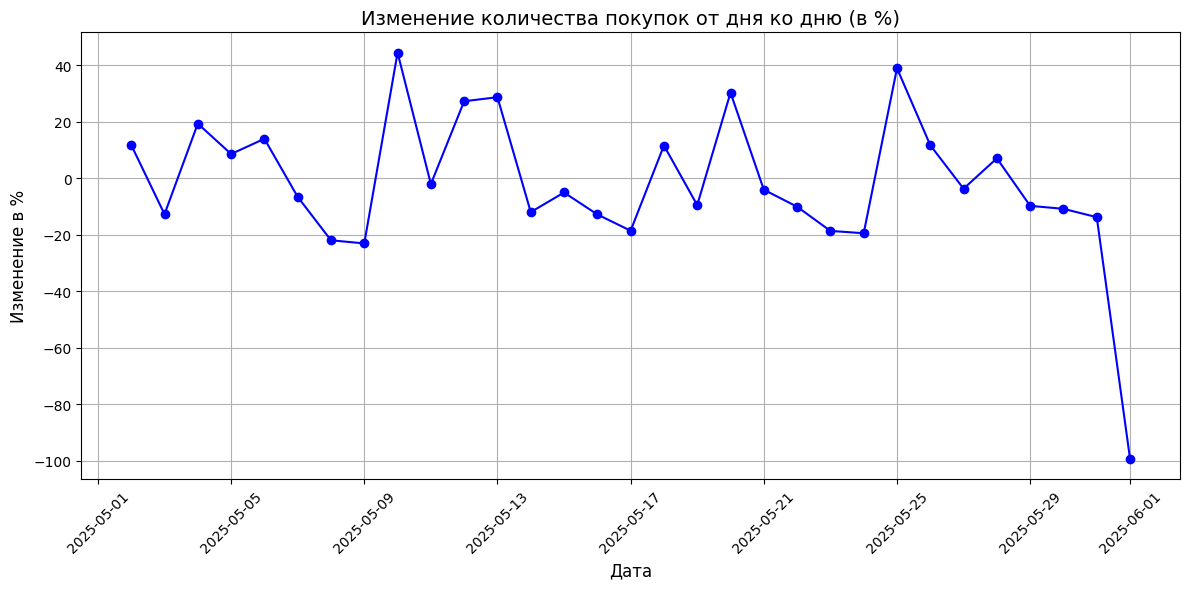

In [90]:
# Сортируем по дате (это критически важно для корректного расчета изменения)
daily_purchases = daily_purchases.sort_values('date')

# Считаем процентное изменение от предыдущего дня
# Метод pct_change() автоматически делает (Текущий / Предыдущий - 1)
daily_purchases['change_pct'] = daily_purchases['purchase_count'].pct_change() * 100

# Удаляем первую строку, где нет предыдущего дня (там будет NaN)
plot_df = daily_purchases.dropna(subset=['change_pct'])

# Строим линейный график
plt.figure(figsize=(12, 6))
plt.plot(plot_df['date'], plot_df['change_pct'], marker='o', linestyle='-', color='blue')
plt.title('Изменение количества покупок от дня ко дню (в %)', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Изменение в %', fontsize=12)
plt.grid(True)
plt.xticks(rotation=45) # Поворот дат, чтобы они не сливались
plt.tight_layout()
plt.show()

### Интерпретация графика 1
- Наблюдается высокая волатильность день ко дню (от -30% до +55%)
- Пик роста +55.17% зафиксирован 10 мая (возможно, выходной день или акция)
- Резкое падение -98.72% 1 июня — артефакт неполной выгрузки
- **Вывод:** Канал требует сглаживания (скользящее среднее) для выявления реальных трендов

### Задача 2. Линейный график  товаров стоимостью > 2000 руб

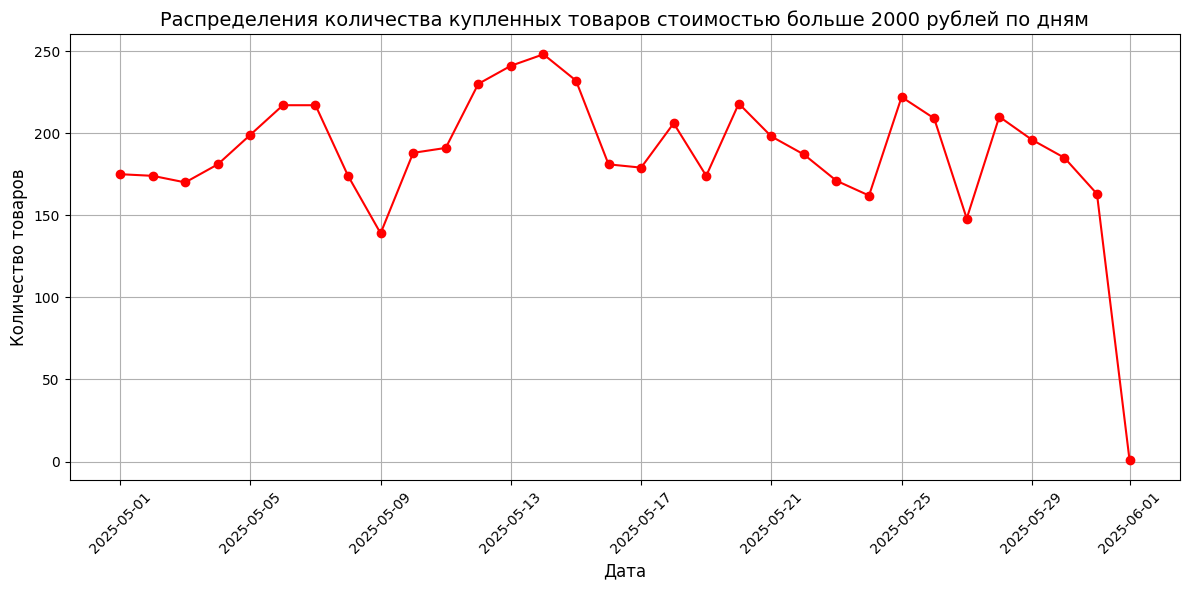

In [91]:
# Оставляем товары со стоимостью > 2000
products_over_2000 = df[df['products_price'] > 2000]

# Считаем кол-во товаров по дням
products_over_2000 = products_over_2000.groupby('date')['products_id'].nunique().reset_index()
products_over_2000 = products_over_2000.rename(columns = {'products_id' : 'products_count'})

# Строим линейный график
plt.figure(figsize=(12, 6))
plt.plot(products_over_2000['date'], products_over_2000['products_count'], marker='o', linestyle='-', color='red')
plt.title('Распределения количества купленных товаров стоимостью больше 2000 рублей по дням', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество товаров', fontsize=12)
plt.grid(True)
plt.xticks(rotation=45) # Поворот дат, чтобы они не сливались
plt.tight_layout()
plt.show()

###  Интерпреция графика 2
- Динамика продаж дорогих товаров коррелирует с общей активностью
- Пики продаж приходятся на середину месяца (10-15 мая)
- **Гипотеза:** Возможна связь с датами выплаты зарплат или промо-акциями

### Задача 3. Столбчатая диаграмма средней стоимости товара по источникам

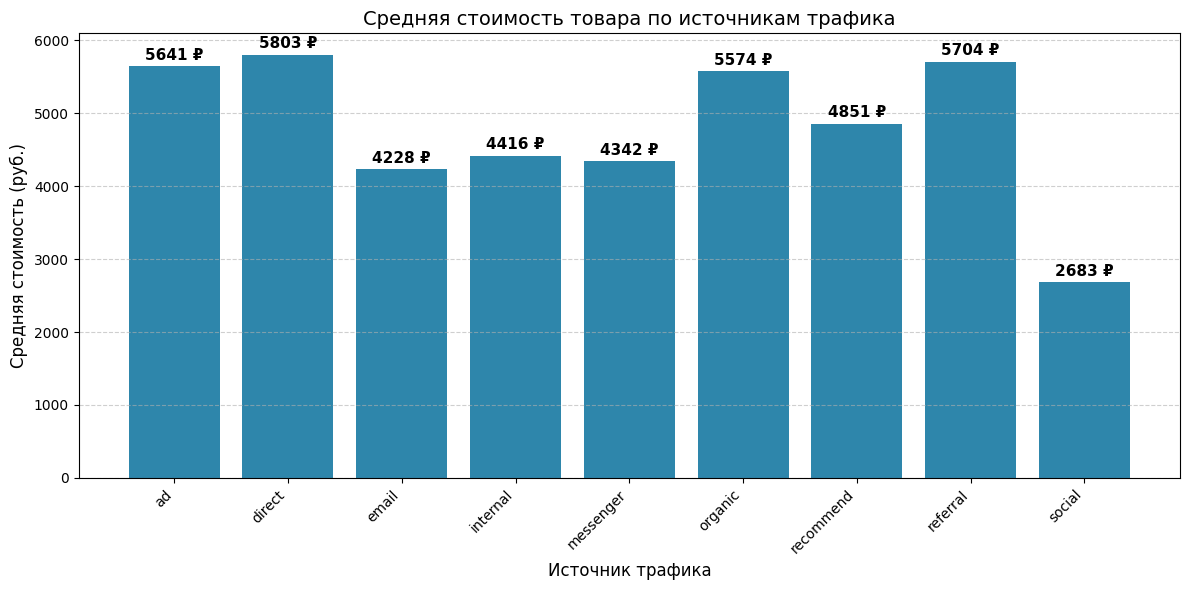

In [92]:
# Отфильтровываем товары с нулевой стоимостью, чтобы избежать занижения метрики за счет бонусных/технических позиций
filtered_df = df[df['products_price'] > 0]

# Рассчитываем среднюю стоимость по источникам
avg_price_per_source = filtered_df.groupby('traffic_source')['products_price'].mean().reset_index()
avg_price_per_source = avg_price_per_source.rename(columns={'products_price': 'avg_price'})

# Строим столбчатую диаграмму
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(avg_price_per_source['traffic_source'], avg_price_per_source['avg_price'], color='#2E86AB')

# Добавляем подписи значений над каждым столбцом
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.,  # Центр столбца по горизонтали
        height + 50,                          # Смещение вверх от верха столбца (подбирается под масштаб данных)
        f'{int(height)} ₽',                   # Текст значения с символом рубля
        ha='center',                          # Горизонтальное выравнивание по центру
        va='bottom',                          # Вертикальное выравнивание по низу текста
        fontsize=11,
        fontweight='bold'                     # Жирный шрифт для лучшей читаемости
    )

plt.title('Средняя стоимость товара по источникам трафика', fontsize=14)
plt.xlabel('Источник трафика', fontsize=12)
plt.ylabel('Средняя стоимость (руб.)', fontsize=12)
plt.xticks(rotation=45, ha='right')  # Поворот подписей и выравнивание, чтобы не обрезались
plt.grid(axis='y', linestyle='--', alpha=0.6)  # Сетка только по вертикали для чистоты
plt.tight_layout()
plt.show()

### Интерпретация графика 3
- Источник `direct` показывает наибольший средний чек — `5803 ₽`
- Источник `social` — наименьший средний чек — `2683 ₽`
- **Рекомендация:** Увеличить инвестиции в канал с высоким средним чеком, проработать стратегию монетизации для канала с низким средним чеком

## Часть 3. SQL-анализ

**Инструмент:** DuckDB (встраиваемая аналитическая СУБД)  
**Преимущества:** Прямая работа с CSV без предварительной загрузки, поддержка оконных функций, CTE, стандарта SQL:2011

### Подключение к данным

In [93]:
import duckdb

In [94]:
# Создаём подключение БД
con = duckdb.connect()

### Задача 1. Количество товаров, купленных в понедельник, в разбивке на источники

In [95]:
query1 = """select p.traffic_source,
                  count(distinct pr.products_id) as products_count
            from purchases as p
            left join products as pr on p.purchase_id = pr.purchase_id
            where extract (isodow from p.purchase_datetime) = 1
            group by p.traffic_source
            order by products_count desc;"""

# Выполняем запрос
result_df1 = con.execute(query1).df()
result_df1

,traffic_source,products_count
0,ad,537
1,organic,455
2,referral,146
3,direct,94
4,email,64
5,internal,20
6,messenger,11
7,social,9
8,recommend,6


### ✅ SQL Задача 1: Покупки в понедельник по источникам

**Результат:** 
             
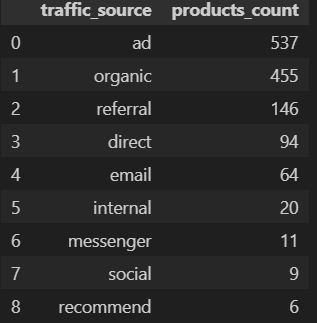

**Наблюдение:** Источник `ad` лидирует по понедельникам — возможно, это связано с поведением B2B-клиентов или началом рабочей недели.

### Задача 2. Товары, которых было куплено больше всего в день (дата, id, цена)

In [96]:
query2 = """with cte1 as (select p.purchase_datetime::date as purchase_date,
                   pr.products_id,
                   pr.products_price,
                   count(*) as products_count 
            from purchases as p
            left join products as pr on p.purchase_id = pr.purchase_id
            group by purchase_date, pr.products_id, pr.products_price),

            cte2 as (select purchase_date,
                   products_id,
                   products_price,
                   dense_rank() over(partition by purchase_date order by products_count desc) as rank
            from cte1)
           
           select purchase_date,
                  products_id,
                  products_price
            from cte2
            where rank = 1
            order by purchase_date;
            """
# Выполняем запрос
result_df2 = con.execute(query2).df()
result_df2

,purchase_date,products_id,products_price
0,2025-05-01,137958,0.0
1,2025-05-02,137958,0.0
2,2025-05-03,137958,0.0
3,2025-05-04,137958,0.0
4,2025-05-05,137958,0.0
5,2025-05-06,137958,0.0
6,2025-05-07,137958,0.0
7,2025-05-08,137958,0.0
8,2025-05-09,137958,0.0
9,2025-05-10,137958,0.0


### SQL Задача 2: Топ-товары по дням

**️ Анализ аномалии:** Товар `products_id = 137958` с ценой 0.0 занимает 1-е место в 31 из 32 дней. Это техническая позиция (доставка/бонусы), которая автоматически добавляется в каждую корзину.

**Альтернативный запрос с фильтрацией платных товаров:**

In [97]:
query2_1 = """with cte1 as (select p.purchase_datetime::date as purchase_date,
                   pr.products_id,
                   pr.products_price,
                   count(*) as products_count 
            from purchases as p
            left join products as pr on p.purchase_id = pr.purchase_id
            where pr.products_price > 0
            group by purchase_date, pr.products_id, pr.products_price),

            cte2 as (select purchase_date,
                   products_id,
                   products_price,
                   dense_rank() over(partition by purchase_date order by products_count desc) as rank
            from cte1)
           
           select purchase_date,
                  products_id,
                  products_price
            from cte2
            where rank = 1
            order by purchase_date;
            """
# Выполняем запрос
result_df2_1 = con.execute(query2_1).df()
result_df2_1

,purchase_date,products_id,products_price
0,2025-05-01,136696,13475.0
1,2025-05-02,820,4560.0
2,2025-05-02,14780,9300.0
3,2025-05-02,293149,675.0
4,2025-05-02,126182,22325.0
...,...,...,...
105,2025-05-31,295197,2493.0
106,2025-05-31,295205,3762.0
107,2025-05-31,153004,2160.0
108,2025-05-31,125310,792.0


**Результат без технических позиций:**

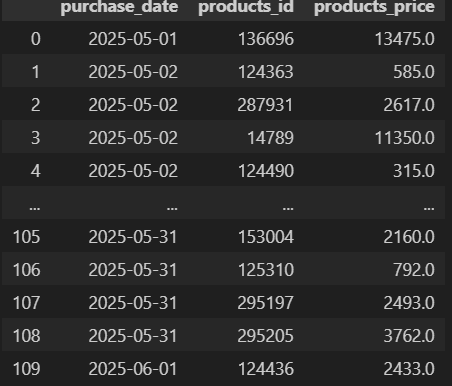

### Задача 3. Три категории товаров

In [98]:
query3 = """select distinct products_id,
                   products_price,
                   case when products_price <= 4000
                   then 'эконом сегмент'
                   when products_price > 4000 and products_price <= 7000
                   then 'средний сегмент'
                   when products_price > 7000
                   then 'премиум сегмент'
                   end as category
            from products
            order by products_id;
            """
# Выполняем запрос
result_df3 = con.execute(query3).df()
result_df3

,products_id,products_price,category
0,15,1400.0,эконом сегмент
1,93,3287.0,эконом сегмент
2,93,4000.0,эконом сегмент
3,133,2490.0,эконом сегмент
4,154,1950.0,эконом сегмент
...,...,...,...
6861,295229,1102.0,эконом сегмент
6862,295245,3555.0,эконом сегмент
6863,295278,0.0,эконом сегмент
6864,295302,0.0,эконом сегмент


In [103]:
query3_1 = """select category,
                   count(*) as products_count
            from (select distinct products_id,
                   products_price,
                   case when products_price <= 4000
                   then 'эконом сегмент'
                   when products_price > 4000 and products_price <= 7000
                   then 'средний сегмент'
                   when products_price > 7000
                   then 'премиум сегмент'
                   end as category
            from products
            order by products_id) as t
            group by category;
            """
# Выполняем запрос
result_df3_1 = con.execute(query3_1).df()
result_df3_1

,category,products_count
0,средний сегмент,1295
1,эконом сегмент,3940
2,премиум сегмент,1631


### SQL Задача 3: Категоризация товаров

**Распределение:**
- Эконом сегмент (≤ 4000 ₽): `3940` товаров (`57%`)
- Средний сегмент (4000-7000 ₽): `1295` товаров (`19%`)
- Премиум сегмент (> 7000 ₽): `1631` товаров (`24%`)

**Примечание:** Товары с ценой 0.0 формально попали в "эконом сегмент". В продакшн-системе их следует вынести в отдельную категорию "технические позиции".

### Задача 4. Топ-5 товаров, которые не покупались дольше всего

In [100]:
query4 = """with cte1 as (select pr.products_id,
                   p.purchase_datetime::date as purchase_date,
                   p.purchase_id,
                   row_number() over(partition by pr.products_id order by p.purchase_datetime::date desc) as rn
            from purchases as p
            left join products as pr on p.purchase_id = pr.purchase_id),
            
            cte2 as (select products_id,
                   purchase_date as last_purchase_date,
                   purchase_id
            from cte1 
            where rn = 1)
            
            select products_id,
                   last_purchase_date,
                   purchase_id
            from cte2
            order by last_purchase_date
            limit 5;
          """
# Выполняем запрос
result_df4 = con.execute(query4).df()
result_df4

,products_id,last_purchase_date,purchase_id
0,125833,2025-05-01,60321273
1,18443,2025-05-01,60321414
2,50115,2025-05-01,60321575
3,124858,2025-05-01,60321251
4,125224,2025-05-01,60321819


### SQL Задача 4: Топ-5 "забытых" товаров

**Результат:** Все 5 товаров имеют последнюю дату покупки 2025-05-01 — первый день выборки.

**Интерпретация:** Это товары, которые покупались только в первый день наблюдений и больше не появлялись. Возможные причины:
- Ограниченная серия/акционный товар
- Ошибка в данных (неполная история)
- Реальное прекращение спроса

**Рекомендация:** Проверить карточки этих товаров — возможно, требуется обновление ассортимента или анализ причин отказа от закупок.

### Задача 5. Среднее количество времени, прошедшее между покупками, в которых был товар с id 293316 в разрезе источников

In [104]:
query5 = """with cte1 as (select p.traffic_source,
                   p.purchase_datetime as purchase_date
            from purchases as p
            left join products as pr on p.purchase_id = pr.purchase_id
            where pr.products_id = 293316),

            cte2 as (select traffic_source,
                   purchase_date,
                   lag(purchase_date) over(partition by traffic_source order by purchase_date) as prev_purchase_date,
                   date_trunc('month', purchase_date)::date - interval '1 day' as last_day_prev_month
            from cte1),

            cte3 as (select traffic_source,
                  purchase_date,
                  case
                     when prev_purchase_date is null
                     then purchase_date - last_day_prev_month
                     else purchase_date - prev_purchase_date
                  end as days_between
                  from cte2)
            
            select traffic_source,
                   round(avg(extract(epoch from days_between) / 86400.0)::numeric, 2) as avg_days_between_purchases 
            from cte3
            group by traffic_source
            order by avg_days_between_purchases desc;
          """
# Выполняем запрос
result_df5 = con.execute(query5).df()
result_df5

,traffic_source,avg_days_between_purchases
0,internal,9.12
1,email,2.48
2,referral,1.82
3,direct,1.08
4,organic,0.42
5,ad,0.35


### SQL Задача 5: Среднее время между покупками товара 293316

**Результат:**

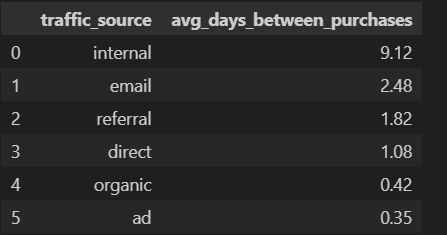

**Методологическое замечание:** Условие о "последнем дне предыдущего месяца" для первой покупки — искусственное допущение. Оно может искажать среднее для источников с малым количеством покупок (например, если первая покупка была 25 мая, интервал до 30 апреля составит 25 дней, что завысит среднее).

**Рекомендация:** Для более точного анализа использовать медиану вместо среднего значения (менее чувствительна к выбросам) или исключить первую покупку из расчёта.

## Заключение и ключевые выводы

### Качество данных
1. **Аномалия нулевых цен:** ~30% товаров имеют цену 0.0 (технические/бонусные позиции). Требуют фильтрации при анализе финансовых метрик.
2. **Артефакт 1 июня:** Неполная выгрузка данных за последний день. Необходимо учитывать при анализе трендов.
3. **Отсутствие дубликатов:** Данные чистые по ключу `purchase_id`.

### Бизнес-инсайты
1. **Канал `organic`** — лидер по разнообразию товаров (2 481 уникальный товар). Сильная позиция для SEO-стратегии.
2. **Пик активности** — 14 мая (413 уникальных товаров). Рекомендуется анализ маркетинговых активностей за эту дату.
3. **Высокая волатильность** день ко дню (до ±55%). Требуется сглаживание для принятия решений.
4. **Товар 293316** — разная частота покупок по источникам. Канал с наименьшим средним интервалом — наиболее лояльный.

### Технические решения
- **Python (Pandas):** Использован для EDA, визуализации, работы с аномалиями
- **Matplotlib:** Построены 3 графика с аннотациями и профессиональным оформлением
- **DuckDB:** Применён для SQL-анализа без необходимости развёртывания СУБД
- **Оконные функции:** `ROW_NUMBER()`, `DENSE_RANK()`, `LAG()` — для решения задач ранжирования и расчёта интервалов

### Рекомендации по улучшению анализа
1. Добавить скользящее среднее (7 дней) для сглаживания волатильности
2. Сегментировать анализ по дням недели (будни/выходные)
3. Провести когортный анализ для оценки retention
4. Исключить технические позиции (цена = 0) из финансового анализа
5. Использовать медиану вместо среднего для метрик с выбросами